In [5]:
import glob
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
import librosa

In [ ]:
sound_dir = r'C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio'
audio_files = glob.glob(os.path.join(sound_dir, "*.flac"))
for file_path in tqdm(audio_files[:750], desc="memproses wak"):
    print(file_path)


memproses wak: 100%|██████████| 750/750 [00:00<00:00, 104118.36it/s]

C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio\002b1299334f4f60b2684134c389988cd855dfe5149810ec3c7b126300b2f396.flac
C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio\0062a08bc8e0b32b9f3e753c2e8d5964f4636b0780b963945c8c857e32416075.flac
C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio\0091d89452bf7b3696af119b4aa1eb5169323b3e863cb23bc5318b4a0d2513b3.flac
C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio\00a82619f41e9c1796477417e4c27aa6220b235a29345021d3bad0c2245100d9.flac
C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio\01187e73163b6d220fb7802507c60631b03bb144c8aed77dc035b0c8a6faf707.flac
C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio\0132d577128b136e65088e679ac0be3e5d729bbb59dec6dec3b15e139bdbcbf8.flac
C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio\0148805f00563

In [ ]:
import librosa
import noisereduce as nr
import soundfile as sf
from IPython.display import Audio, display

y, sr = librosa.load("audio_test.flac", sr=22050)


y_denoised = nr.reduce_noise(y=y, sr=sr, stationary=True, prop_decrease=0.8)

y_trimmed, _ = librosa.effects.trim(y_denoised, top_db=20)
y_clean = librosa.util.normalize(y_trimmed)

print("Audio Asli:")
display(Audio(data=y, rate=sr))

print("Audio Setelah Noise Reduction & Cleaning:")
display(Audio(data=y_clean, rate=sr))

sf.write("suara_sangat_bersih.wav", y_clean, sr)

Audio Asli:


Audio Setelah Noise Reduction & Cleaning:


In [9]:
import pandas as pd
df = pd.read_csv('ektsrak_audio_test.csv')

In [21]:
df_copy = df.drop(columns=['file_name'])
df_copy

,duration_sec,rms_energy,zcr,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12,mfcc_13
0,7.142222,0.161299,0.166770,5.283679,77.809395,3.312421,14.772315,-5.693192,5.841712,-3.533522,-1.641090,-1.213793,1.834021,-3.963088,3.185452,-2.454439
1,12.853878,0.070664,0.339801,-77.635340,33.075134,6.441496,15.748579,1.938775,15.226568,-9.405733,2.819425,3.943699,1.557044,8.647038,-6.301935,-1.968492
2,10.541315,0.111485,0.268490,-25.358776,42.484380,-30.211071,-9.131110,-18.595858,-2.676572,-7.911592,-0.573311,-2.843875,5.456455,-3.055626,3.681920,0.618338
3,12.411429,0.114339,0.347005,-56.762480,17.940813,2.353224,13.771561,-9.837737,-1.756369,-9.662498,-6.080697,-10.481232,11.839758,0.456594,-4.273437,-7.001799
4,9.414286,0.100804,0.162046,-131.231960,94.358150,-11.438562,35.352654,5.789201,-2.373148,7.513721,16.776045,-4.794737,8.571301,2.418611,1.244642,1.045562
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
809,12.842812,0.137693,0.315874,-149.173260,-3.835173,-29.498455,86.175860,-2.689911,-3.668802,8.939993,21.612492,19.944450,-26.064386,12.178926,15.224541,-15.110925
810,6.768345,0.139232,0.148526,-60.350480,90.446500,-10.467461,40.587116,-6.772581,15.717874,-1.024878,13.923182,-8.715456,-1.186099,-7.895948,-10.107404,-8.365272
811,11.096825,0.118739,0.133272,-54.040565,90.108475,1.724447,12.936161,-5.630564,9.176520,-0.269225,7.823949,0.989586,5.843536,-1.323864,2.470617,-3.909653
812,11.810385,0.115042,0.420385,-44.588528,-8.485003,2.269976,27.423647,4.088905,14.541053,-2.898649,12.023310,7.048203,-8.718489,3.290634,14.307532,-5.610245


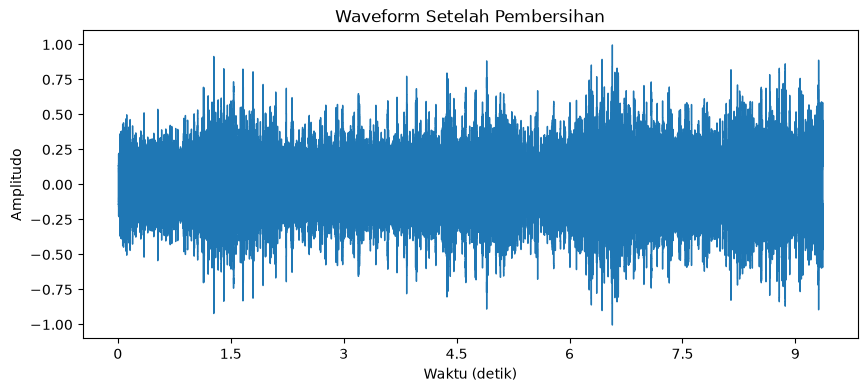

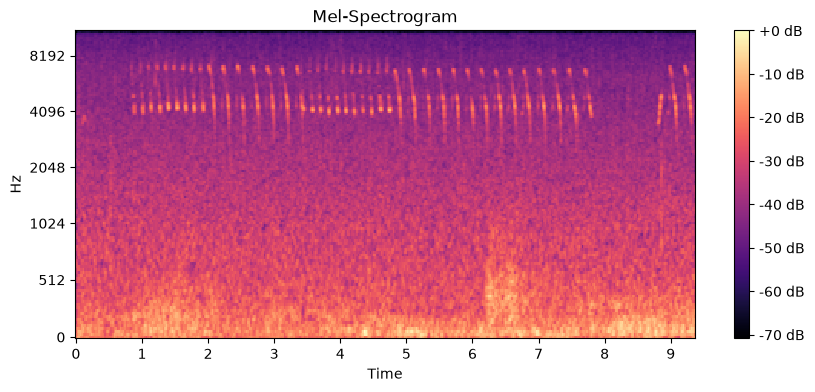

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

file_path = "suara_before.wav"
y, sr = librosa.load(file_path, sr=None) 

y_trimmed, index = librosa.effects.trim(y, top_db=20)

y_normalized = librosa.util.normalize(y_trimmed)

plt.figure(figsize=(10, 4))
librosa.display.waveshow(y_normalized, sr=sr)
plt.title("Waveform Setelah Pembersihan")
plt.xlabel("Waktu (detik)")
plt.ylabel("Amplitudo")
plt.show()

mel_spectrogram = librosa.feature.melspectrogram(y=y_normalized, sr=sr)
mel_db = librosa.power_to_db(mel_spectrogram, ref=np.max)

plt.figure(figsize=(10, 4))
librosa.display.specshow(mel_db, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title("Mel-Spectrogram")
plt.show()

In [ ]:

import os
import json
import itertools
import numpy as np
import pandas as pd
import librosa
import noisereduce as nr
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from scipy.signal import butter, sosfilt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score
from torch.utils.data import Dataset, DataLoader

CFG = dict(
    train_csv="data/metadata.csv",          
    test_csv="data/sample_submission.csv", 
    train_dir=r"C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio",
    test_dir=r"C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\test\audio",
    ext=".flac",
    sr=32000,
    duration=5,                       
    hp_cutoff=400,                    
    n_mels=128, fmax=8000, n_fft=2048, hop=512,
    classes=["Bondol Jawa", "Cendrawasih", "Kutilang"],
    archs=["resnet18", "efficientnet_b0"],
    n_folds=5, epochs=15, bs=32, lr=1e-3,
    unknown_thr_grid=np.arange(0.30, 0.95, 0.01),
    device="cuda" if torch.cuda.is_available() else "cpu",
    wd=1e-2,
    num_workers=0,    
    seed=42,
    use_grid=True,
    gs_folds=3,      
    gs_epochs=6,      
    
)

GRID = dict(
    lr=[3e-4, 1e-3],
    wd=[1e-2, 1e-4],
    n_mels=[96, 128],
    hp_cutoff=[300, 500],
)
CLS2ID = {c: i for i, c in enumerate(CFG["classes"])}
SEG = CFG["sr"] * CFG["duration"]



def highpass(y, sr, cutoff):
    sos = butter(5, cutoff, btype="highpass", fs=sr, output="sos")
    return sosfilt(sos, y).astype(np.float32)


def load_clean(path):
    y, _ = librosa.load(path, sr=CFG["sr"], mono=True)
    y = highpass(y, CFG["sr"], CFG["hp_cutoff"])
    try:
        y = nr.reduce_noise(y=y, sr=CFG["sr"], stationary=True, prop_decrease=0.8)
    except Exception:
        pass
    y_trim, _ = librosa.effects.trim(y, top_db=30)
    if len(y_trim) > CFG["sr"] // 2:  
        y = y_trim
    return y.astype(np.float32)


def fix_length(y, train=False):
    if len(y) < SEG:
        return np.pad(y, (0, SEG - len(y)), mode="wrap")
    start = np.random.randint(0, len(y) - SEG + 1) if train else (len(y) - SEG) // 2
    return y[start:start + SEG]


def to_chunks(y):
    if len(y) <= SEG:
        return [fix_length(y)]
    return [y[i:i + SEG] for i in range(0, len(y) - SEG + 1, SEG)] or [fix_length(y)]


def mel_db(y):
    m = librosa.feature.melspectrogram(
        y=y, sr=CFG["sr"], n_fft=CFG["n_fft"], hop_length=CFG["hop"],
        n_mels=CFG["n_mels"], fmax=CFG["fmax"])
    m = librosa.power_to_db(m, ref=np.max)
    m = (m - m.mean()) / (m.std() + 1e-6)
    return m.astype(np.float32) 

def add_noise_snr(y, snr_db):
    noise = np.random.randn(len(y)).astype(np.float32)
    noise = np.convolve(noise, np.ones(8) / 8, mode="same")
    p_sig, p_noise = np.mean(y ** 2) + 1e-9, np.mean(noise ** 2) + 1e-9
    scale = np.sqrt(p_sig / (p_noise * 10 ** (snr_db / 10)))
    return y + scale * noise


def wave_augment(y):
    if np.random.rand() < 0.5:                      
        y = np.roll(y, np.random.randint(-SEG // 5, SEG // 5))
    if np.random.rand() < 0.5:                     
        y = add_noise_snr(y, np.random.uniform(5, 20))
    if np.random.rand() < 0.2:                       
        y = librosa.effects.pitch_shift(y, sr=CFG["sr"], n_steps=np.random.uniform(-1, 1))
    return y


def spec_augment(m, n_freq=2, n_time=2, max_f=16, max_t=30):
    m = m.copy()
    n_mels, T = m.shape
    for _ in range(n_freq):
        f = np.random.randint(0, max_f)
        f0 = np.random.randint(0, max(1, n_mels - f))
        m[f0:f0 + f, :] = 0
    for _ in range(n_time):
        t = np.random.randint(0, max_t)
        t0 = np.random.randint(0, max(1, T - t))
        m[:, t0:t0 + t] = 0
    return m


class BirdDS(Dataset):
    def __init__(self, waves, labels=None, train=False):
        self.waves, self.labels, self.train = waves, labels, train

    def __len__(self):
        return len(self.waves)

    def __getitem__(self, i):
        y = fix_length(self.waves[i], train=self.train)
        if self.train:
            y = wave_augment(y)
        m = mel_db(y)
        if self.train:
            m = spec_augment(m)
        x = torch.from_numpy(m).unsqueeze(0) 
        if self.labels is None:
            return x
        return x, self.labels[i]



def make_model(arch):
    return timm.create_model(arch, pretrained=True, num_classes=len(CFG["classes"]), in_chans=1)


def train_one_fold(arch, tr_w, tr_y, va_w, va_y):
    dev = CFG["device"]
    model = make_model(arch).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["wd"])
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=CFG["lr"], epochs=CFG["epochs"],
        steps_per_epoch=int(np.ceil(len(tr_w) / CFG["bs"])))
    crit = nn.CrossEntropyLoss()
    tr_dl = DataLoader(BirdDS(tr_w, tr_y, True), batch_size=CFG["bs"], shuffle=True,
                       num_workers=CFG["num_workers"], drop_last=True)
    best, best_state = -1, None
    for ep in range(CFG["epochs"]):
        model.train()
        for x, y in tr_dl:
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward()
            opt.step()
            sched.step()
        logits = predict_logits(model, va_w)
        f1 = f1_score(va_y, logits.argmax(1), average="macro")
        print(f"  [{arch}] epoch {ep + 1}/{CFG['epochs']} val macroF1={f1:.4f}")
        if f1 > best:
            best, best_state = f1, {k: v.cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model


@torch.no_grad()
def predict_logits(model, waves):
    model.eval()
    dev = CFG["device"]
    out = []
    for y in waves:
        x = torch.stack([torch.from_numpy(mel_db(c)).unsqueeze(0) for c in to_chunks(y)]).to(dev)
        out.append(model(x).mean(0).cpu().numpy())
    return np.stack(out)



def fit_temperature(logits, labels):
    logits = torch.tensor(logits, dtype=torch.float32)
    labels = torch.tensor(labels)
    T = nn.Parameter(torch.ones(1))
    opt = torch.optim.LBFGS([T], lr=0.1, max_iter=100)

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(logits / T.clamp(min=0.05), labels)
        loss.backward()
        return loss
    opt.step(closure)
    return float(T.clamp(min=0.05).item())


def softmax(logits, T=1.0):
    z = logits / T
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def entropy(p):
    return -(p * np.log(p + 1e-9)).sum(1)


def tune_threshold(probs, y_true, groups, n_trials=30, frac=0.15, seed=0, verbose=True):
    
    rng = np.random.RandomState(seed)
    uniq = np.unique(groups)
    msp = probs.max(1)
    pred_known = probs.argmax(1)
    scores = np.zeros(len(CFG["unknown_thr_grid"]))
    for _ in range(n_trials):
        k = max(1, int(len(uniq) * frac))
        unk_groups = rng.choice(uniq, size=k, replace=False)
        is_unk = np.isin(groups, unk_groups)
        truth = np.where(is_unk, 3, y_true)
        for j, thr in enumerate(CFG["unknown_thr_grid"]):
            pred = np.where(msp < thr, 3, pred_known)
            scores[j] += f1_score(truth, pred, average="macro", labels=[0, 1, 2, 3])
    scores /= n_trials
    best = int(scores.argmax())
    if verbose:
        print(f"Best threshold={CFG['unknown_thr_grid'][best]:.2f} (macroF1 sintetis={scores[best]:.4f})")
    return float(CFG["unknown_thr_grid"][best]), float(scores[best])



def resolve_paths(df, root, ext):
    print(f"Mencari audio di: {os.path.abspath(root)}")
    if not os.path.isdir(root):
        raise FileNotFoundError(
            f"Folder '{root}' tidak ditemukan. Working dir sekarang: {os.getcwd()}. "
            f"Isi CFG train_dir/test_dir dengan path absolut.")
    idx = {}
    for dp, _, fs in os.walk(root):
        for f in fs:
            if f.lower().endswith(ext.lower()):
                idx[os.path.splitext(f)[0]] = os.path.join(dp, f)
    ids = [str(f)[:-len(ext)] if ext and str(f).endswith(ext) else str(f) for f in df["file_id"]]
    missing = [i for i in ids if i not in idx]
    print(f"  {len(ids) - len(missing)}/{len(ids)} file ditemukan ({len(idx)} file {ext} di folder)")
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} file tidak ditemukan, contoh: {missing[:3]}. "
            f"Cek ekstensi (CFG['ext']), isi kolom file_id, dan path folder.")
    paths = [idx[i] for i in ids]
    try:  
        with open(paths[0], "rb") as fh:
            fh.read(16)
    except OSError as e:
        raise OSError(
            f"File ada tapi tidak bisa dibaca: {paths[0]} ({e}). "
            f"Jika di OneDrive: klik kanan folder > 'Always keep on this device', "
            f"atau pindahkan dataset ke luar OneDrive (mis. C:\\data).")
    return paths


def get_waves(cutoff, cache, train, test):
    if cutoff not in cache:
        print(f"Preprocessing audio (hp_cutoff={cutoff} Hz)...")
        CFG["hp_cutoff"] = cutoff
        tr = [load_clean(p) for p in train["path"]]
        te = [load_clean(p) for p in test["path"]]
        cache[cutoff] = (tr, te)
    return cache[cutoff]


def run_cv(arch, tr_waves, y_all, groups, n_folds, te_waves=None, save=False):
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=CFG["seed"])
    oof = np.zeros((len(y_all), 3), dtype=np.float32)
    te_logits = []
    for fold, (tr_idx, va_idx) in enumerate(sgkf.split(tr_waves, y_all, groups)):
        assert set(groups[tr_idx]).isdisjoint(groups[va_idx]), "Group bocor antar fold!"
        print(f"\n=== {arch} | fold {fold + 1}/{n_folds} ===")
        model = train_one_fold(
            arch,
            [tr_waves[i] for i in tr_idx], y_all[tr_idx],
            [tr_waves[i] for i in va_idx], y_all[va_idx])
        oof[va_idx] = predict_logits(model, [tr_waves[i] for i in va_idx])
        if te_waves is not None:
            te_logits.append(predict_logits(model, te_waves))
        if save:
            torch.save(model.state_dict(), f"{arch}_fold{fold}.pt")
    return oof, te_logits


def grid_search(arch, train, test, y_all, groups, cache):
  
    keys = list(GRID)
    orig = {k: CFG[k] for k in keys + ["epochs", "n_folds"]}
    results = []
    combos = list(itertools.product(*GRID.values()))
    for ci, vals in enumerate(combos, 1):
        params = dict(zip(keys, vals))
        print(f"\n##### GRID [{arch}] {ci}/{len(combos)}: {params}")
        CFG.update(params)
        CFG["epochs"] = CFG["gs_epochs"]
        tr_w, _ = get_waves(params["hp_cutoff"], cache, train, test)
        CFG["hp_cutoff"] = params["hp_cutoff"]
        oof, _ = run_cv(arch, tr_w, y_all, groups, CFG["gs_folds"])
        p = softmax(oof, fit_temperature(oof, y_all))
        f1_known = f1_score(y_all, p.argmax(1), average="macro")
        thr, f1_unk = tune_threshold(p, y_all, groups, n_trials=10, verbose=False)
        print(f"-> macroF1(3 kelas)={f1_known:.4f} | macroF1(4 kelas, Unknown sintetis)={f1_unk:.4f} | thr={thr:.2f}")
        results.append({**params, "arch": arch, "f1_known": f1_known, "f1_unk": f1_unk, "thr": thr})

    CFG.update(orig)  # kembalikan epochs/n_folds ke nilai final
    df = pd.DataFrame(results).sort_values("f1_unk", ascending=False)
    df.to_csv(f"gridsearch_{arch}.csv", index=False)
    print(f"\nHasil grid search {arch}:\n", df.to_string(index=False))
    best = df.iloc[0]
    return {k: (type(GRID[k][0])(best[k])) for k in keys}



def main():
    np.random.seed(CFG["seed"])
    torch.manual_seed(CFG["seed"])

    train = pd.read_csv(CFG["train_csv"])
    test = pd.read_csv(CFG["test_csv"])
    train["path"] = resolve_paths(train, CFG["train_dir"], CFG["ext"])
    test["path"] = resolve_paths(test, CFG["test_dir"], CFG["ext"])
    y_all = train["label"].map(CLS2ID).values
    groups = train["source_group"].values
    cache = {}

    oof_probs, test_probs, best_params = [], [], {}
    for arch in CFG["archs"]:
        
        if CFG["use_grid"]:
            best = grid_search(arch, train, test, y_all, groups, cache)
            CFG.update(best)
            best_params[arch] = best
            print(f"\n>>> Parameter terbaik {arch}: {best}")

        tr_w, te_w = get_waves(CFG["hp_cutoff"], cache, train, test)
        CFG["hp_cutoff"] = CFG["hp_cutoff"]
        oof, te_logits = run_cv(arch, tr_w, y_all, groups, CFG["n_folds"], te_w, save=True)

        T = fit_temperature(oof, y_all)
        print(f"{arch}: temperature={T:.3f}")
        oof_probs.append(softmax(oof, T))
        test_probs.append(np.mean([softmax(l, T) for l in te_logits], axis=0))

    if best_params:
        with open("best_params.json", "w") as f:
            json.dump(best_params, f, indent=2)

    oof_p = np.mean(oof_probs, axis=0)
    test_p = np.mean(test_probs, axis=0)
    print("OOF macroF1 (3 kelas):", f1_score(y_all, oof_p.argmax(1), average="macro"))
    thr, _ = tune_threshold(oof_p, y_all, groups)

    # LANGKAH 7: submission
    pred = np.where(test_p.max(1) < thr, "Unknown",
                    np.array(CFG["classes"])[test_p.argmax(1)])
    sub = pd.DataFrame({"file_id": test["file_id"], "label": pred})
    assert list(sub.columns) == ["file_id", "label"]
    assert sub["label"].isin(CFG["classes"] + ["Unknown"]).all()
    sub.to_csv("submission.csv", index=False)
    print(sub["label"].value_counts())


if __name__ == "__main__":
    main()

Mencari audio di: C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\train\audio
  1826/1826 file ditemukan (1826 file .flac di folder)
Mencari audio di: C:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\data\schematics-2026\test\audio
  814/814 file ditemukan (814 file .flac di folder)

##### GRID [resnet18] 1/16: {'lr': 0.0003, 'wd': 0.01, 'n_mels': 96, 'hp_cutoff': 300}
Preprocessing audio (hp_cutoff=300 Hz)...

=== resnet18 | fold 1/3 ===


c:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\local_ypfz2f8\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWa

  [resnet18] epoch 1/6 val macroF1=0.4439


c:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


  [resnet18] epoch 2/6 val macroF1=0.6096


...

c:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


  [resnet18] epoch 5/6 val macroF1=0.6202


c:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\local_ypfz2f8\OneDrive\Dokumen\UTScode\.venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


  [resnet18] epoch 6/6 val macroF1=0.6138
-> macroF1(3 kelas)=0.6021 | macroF1(4 kelas, Unknown sintetis)=0.4690 | thr=0.63

##### GRID [resnet18] 2/16: {'lr': 0.0003, 'wd': 0.01, 'n_mels': 96, 'hp_cutoff': 500}
Preprocessing audio (hp_cutoff=500 Hz)...


KeyboardInterrupt: 